In [1]:
# NAME: Bruce Bai 
# GITHUB HANDLE: bruceb002 
# STUDENT ID: 1563103829 

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, FunctionTransformer

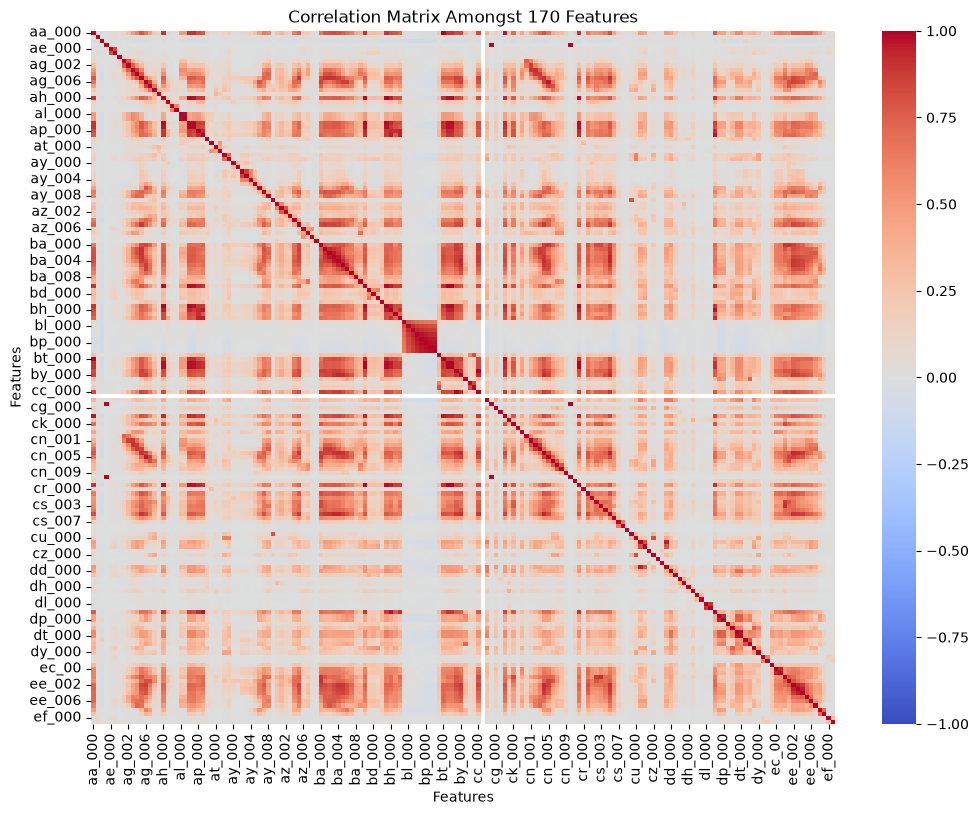

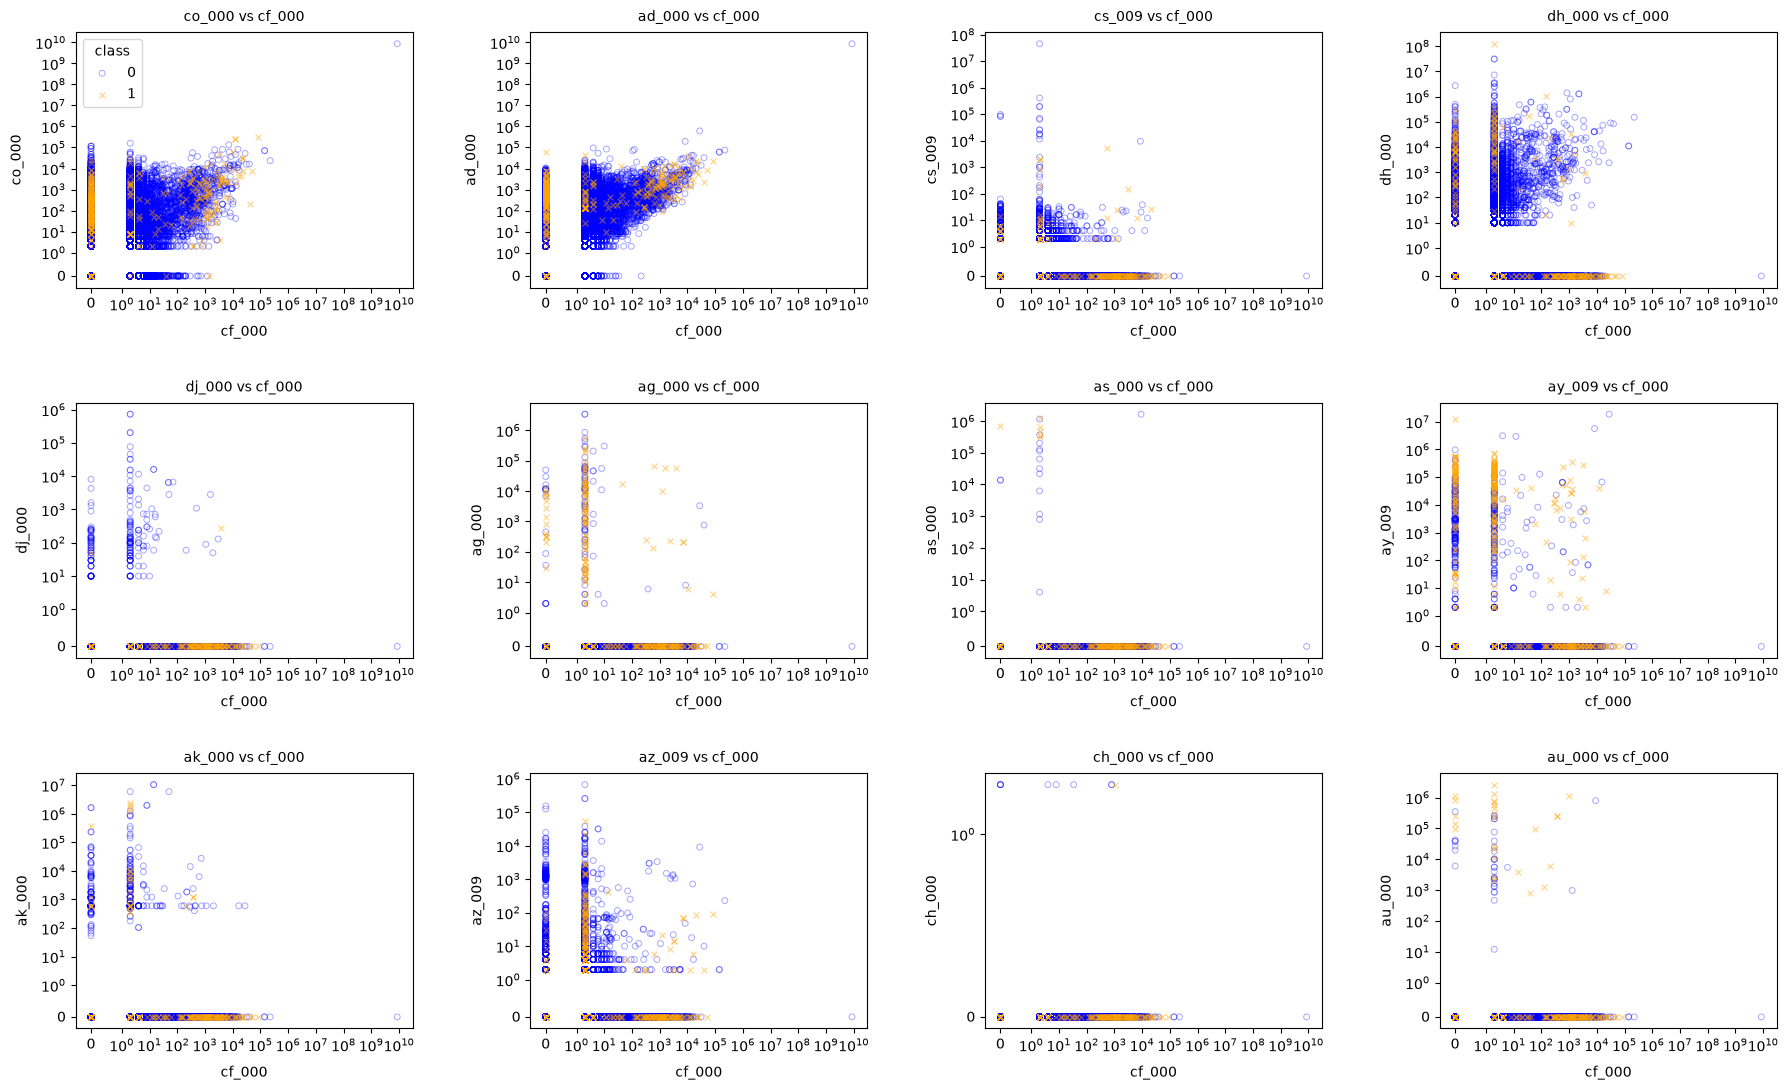

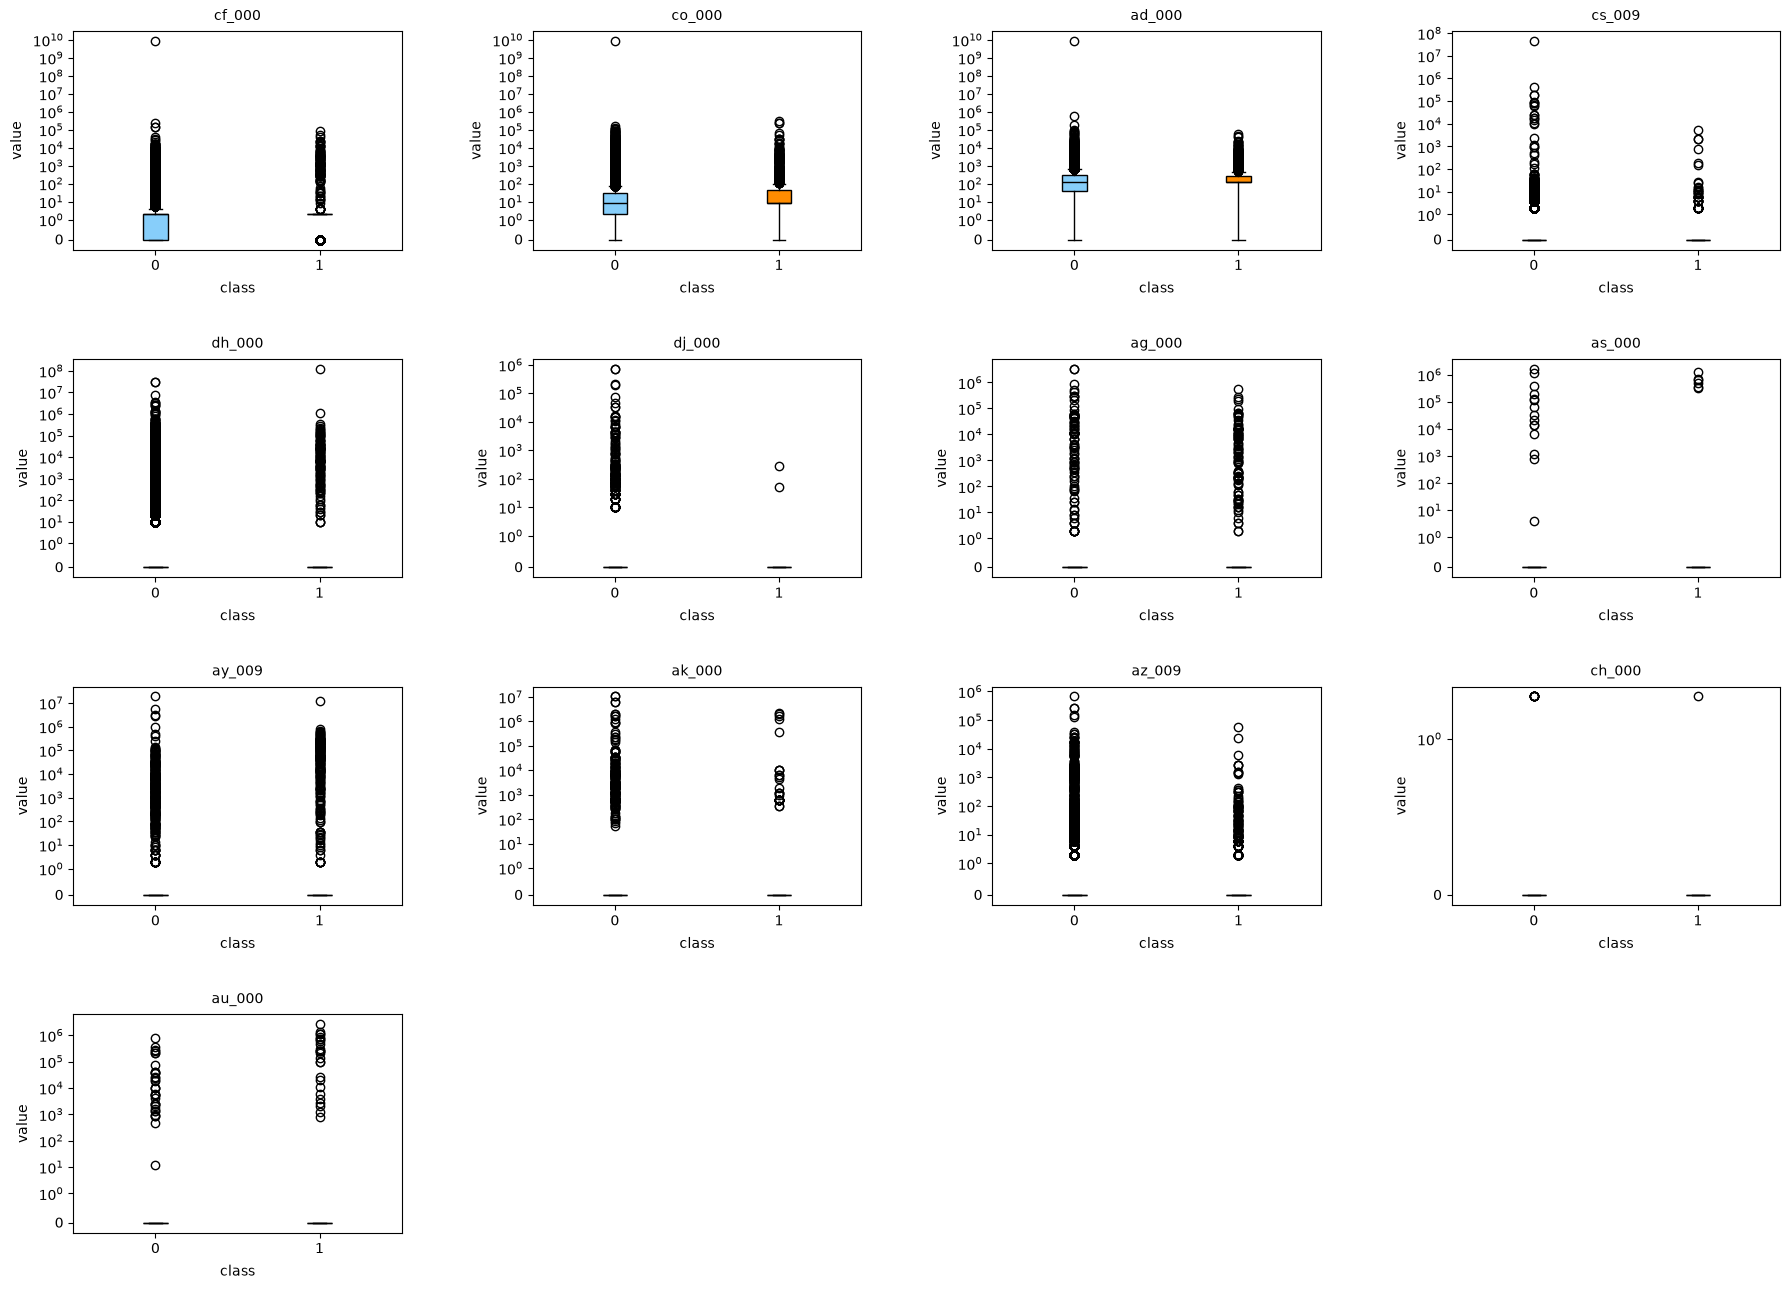


Most of the selected features have highly skewed distributions, with at least 75% of observations equal to zero in both classes for 10 of the 13 features. As a result, their interquartile ranges are zero, producing collapsed box plots. Numerous extreme observations are also present. While some differences between the positive and negative classes can be observed, the scatter plots and box plots alone are insufficient to establish the statistical significance or predictive importance of these features.


In [2]:
# 1a) Download data
train_df = pd.read_csv("../data/aps_failure_training_set.csv", skiprows=20, na_values="na")
test_df = pd.read_csv("../data/aps_failure_test_set.csv", skiprows=20, na_values="na")
train_df["class"] = train_df["class"].map({"neg": 0, "pos": 1})
test_df["class"] = test_df["class"].map({"neg": 0, "pos": 1})

# 1b)i. Data Imputation: Using median imputation to handle missing values
## Not included in asgn: Ran experiments to determine median imputation is one of the most fit / successful methods on dataset
X_train, X_test = train_df.drop(columns=["class"]), test_df.drop(columns=["class"])
y_train, y_test = train_df["class"], test_df["class"]

imputer = SimpleImputer(strategy="median")
imputed_X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
imputed_X_test = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

# 1b)ii. Calculating CV
s, m = imputed_X_train.std(), imputed_X_train.mean()
CV = s / m

# 1b)iii. Correlation Matrix
correlation_matrix = imputed_X_train.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Matrix Amongst 170 Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.show()

# iv. plots for highest floor(sqrt(170))=13 CV features
top13 = CV.nlargest(13)

## Graphing Scatterplots
plot_df = imputed_X_train[top13.index].copy()
plot_df["class"] = y_train.values

x_feature = top13.index[0]
other_features = top13.index[1:]

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
axes = axes.flatten()

for i, feature in enumerate(other_features):
    ax = axes[i]

    class0 = plot_df[plot_df["class"] == 0]
    class1 = plot_df[plot_df["class"] == 1]

    ax.scatter(
        class0[x_feature], class0[feature], marker="o", facecolors="none", edgecolors="blue", 
        alpha=0.35, s=18, linewidths=0.7, label="0" if i == 0 else None
    )

    ax.scatter(
        class1[x_feature], class1[feature], marker="x", c="orange",
        alpha=0.5, s=18, linewidths=0.8, label="1" if i == 0 else None
    )

    ax.set_xscale("symlog", linthresh=1)
    ax.set_yscale("symlog", linthresh=1)
    ax.set_xlabel(x_feature, labelpad=8)
    ax.set_ylabel(feature, labelpad=8)
    ax.set_title(f"{feature} vs {x_feature}", fontsize=10, pad=8)

axes[0].legend(title="class")

plt.tight_layout()
plt.subplots_adjust(hspace=0.45, wspace=0.35)
plt.show()

## Graphing Box Plots
fig, axes = plt.subplots(4, 4, figsize=(18, 13))
axes = axes.flatten()

for i, feature in enumerate(top13.index):
    ax = axes[i]

    class0_vals = plot_df[plot_df["class"] == 0][feature]
    class1_vals = plot_df[plot_df["class"] == 1][feature]

    bp = ax.boxplot([class0_vals, class1_vals], tick_labels=["0", "1"], patch_artist=True)

    for box, color in zip(bp["boxes"], ["lightskyblue", "darkorange"]):
        box.set_facecolor(color)

    for median in bp["medians"]:
        median.set_color("black")

    ax.set_title(feature, fontsize=10, pad=8)
    ax.set_xlabel("class", labelpad=6)
    ax.set_ylabel("value", labelpad=6)
    ax.set_yscale("symlog", linthresh=1)

for j in range(len(top13), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.subplots_adjust(hspace=0.5, wspace=0.4)
plt.show()
print("")

print("Most of the selected features have highly skewed distributions, with at least 75% of observations equal to zero in both \
classes for 10 of the 13 features. As a result, their interquartile ranges are zero, producing collapsed box plots. Numerous \
extreme observations are also present. While some differences between the positive and negative classes can be observed, the \
scatter plots and box plots alone are insufficient to establish the statistical significance or predictive importance of \
these features.")

In [3]:
# 1b)v. Analyzing imbalance of dataset
print(y_train.value_counts())
print(y_test.value_counts())
print("")

print("The training dataset contains 59,000 negative observations (~98.33%) and 1,000 positive observations (~1.67%), while the test \
dataset contains 15,625 negative observations (~97.66%) and 375 positive observations (~2.34%). Therefore, both datasets are pretty \
imbalanced, with the negative class significantly outnumbering the positive class. This imbalance may cause classifiers to favor \
the majority class, making accuracy alone an insufficient measure of classification performance.")

class
0    59000
1     1000
Name: count, dtype: int64
class
0    15625
1      375
Name: count, dtype: int64

The training dataset contains 59,000 negative observations (~98.33%) and 1,000 positive observations (~1.67%), while the test dataset contains 15,625 negative observations (~97.66%) and 375 positive observations (~2.34%). Therefore, both datasets are pretty imbalanced, with the negative class significantly outnumbering the positive class. This imbalance may cause classifiers to favor the majority class, making accuracy alone an insufficient measure of classification performance.



--- TRAINING RESULTS ---
Confusion Matrix:
 [[59000     0]
 [    0  1000]]
AUC: 1.0000
Misclassification Rate: 0.00000000

--- TESTING RESULTS ---
Confusion Matrix:
 [[15609    16]
 [  108   267]]
AUC: 0.9928
Misclassification Rate: 0.00775000

OOB Error: 0.0058
Test Error: 0.0077


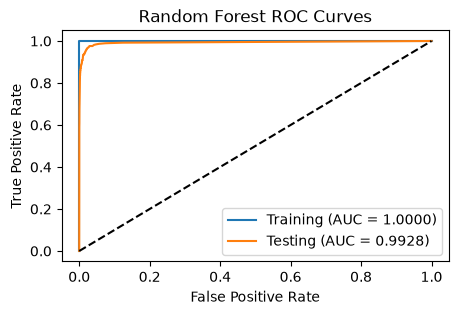


The Random Forest achieved a perfect training confusion matrix with zero misclassified records (ie. misclassification rate of 0), and the training ROC curve having an AUC of 1.0, meaning it correctly classified all training observations. On the test set, the confusion matrix had 16 false positives and 108 false negatives. The test ROC curve also showed strong performance, with an AUC of 0.9928 and a misclassification rate of 0.0077 (0.77%).

The Out-of-Bag (OOB) error estimate was 0.0058 (0.58%), which is fairly close to the test error of 0.0077 (0.77%). This suggests that the OOB error provides a reasonable estimate of the model's performance on unseen data, despite the perfect training accuracy. However, while the overall accuracy is very high, the model still incorrectly classified 108 out of 375 positive test observations (~28.8%). This suggests that the model has more difficulty identifying positive cases, likely partially due to the class imbalance.


In [4]:
# 1c) Training Random Forest
rf = RandomForestClassifier(n_estimators=200, oob_score=True, random_state=1313, n_jobs=-1)
rf.fit(imputed_X_train, y_train)

plt.figure(figsize=(5, 3))

# helper function re-usable for any model
def evaluate_model(model, dataset_type, X, y):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]

    cm = confusion_matrix(y, y_pred, labels=[0, 1])
    error = (y_pred != y).mean()
    auc = roc_auc_score(y, y_prob)

    fpr, tpr, _ = roc_curve(y, y_prob)
    plt.plot(fpr, tpr, label=f"{dataset_type} (AUC = {auc:.4f})")

    print(f"\n--- {dataset_type.upper()} RESULTS ---")
    print("Confusion Matrix:\n", cm)
    print(f"AUC: {auc:.4f}")
    print(f"Misclassification Rate: {error:.8f}")

    return error

errors = {}
errors["Training"] = evaluate_model(rf, "Training", imputed_X_train, y_train)
errors["Testing"] = evaluate_model(rf, "Testing", imputed_X_test, y_test)

# Obtaining Out of Bag Error
oob_error = 1 - rf.oob_score_

print(f"\nOOB Error: {oob_error:.4f}")
print(f"Test Error: {errors['Testing']:.4f}")

plt.plot([0, 1], [0, 1], color="black", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.show()

print("")
print("The Random Forest achieved a perfect training confusion matrix with zero misclassified records (ie. misclassification rate of 0), \
and the training ROC curve having an AUC of 1.0, meaning it correctly classified all training observations. On the test set, the \
confusion matrix had 16 false positives and 108 false negatives. The test ROC curve also showed strong performance, with an AUC of \
0.9928 and a misclassification rate of 0.0077 (0.77%).\n")
print("The Out-of-Bag (OOB) error estimate was 0.0058 (0.58%), which is fairly close to the test error of 0.0077 (0.77%). This \
suggests that the OOB error provides a reasonable estimate of the model's performance on unseen data, despite the perfect training \
accuracy. However, while the overall accuracy is very high, the model still incorrectly classified 108 out of 375 positive test \
observations (~28.8%). This suggests that the model has more difficulty identifying positive cases, likely partially due to the class \
imbalance.")


--- TRAINING RESULTS ---
Confusion Matrix:
 [[59000     0]
 [    0  1000]]
AUC: 1.0000
Misclassification Rate: 0.00000000

--- TESTING RESULTS ---
Confusion Matrix:
 [[15607    18]
 [  163   212]]
AUC: 0.9931
Misclassification Rate: 0.01131250

OOB Error: 0.0077
Test Error: 0.0113


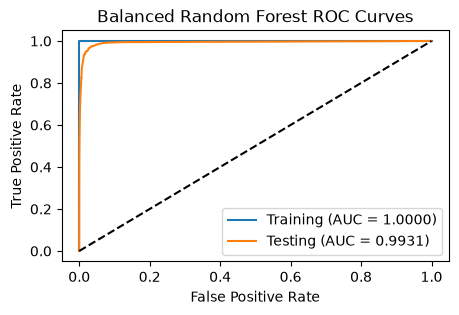


To address class imbalance, I used class_weight='balanced_subsample', which adjusts class weights for each tree's bootstrap sample to give the minority class more importance during training. The balanced Random Forest achieved perfect training performance yet again. On the test set, its AUC improved slightly compared to 1c), suggesting that it was marginally better at distinguishing between the two classes overall. However, both the test misclassification rate and OOB error increased, suggesting worse classification performance despite the slight improvement in AUC. In particular, the model produced more false negatives, meaning it became less effective at identifying actual APS failures. Therefore, class weighting did not improve the Random Forest's classification performance in this experiment.


In [5]:
# 1d) Compensating for Class Imbalance in RF
rf_balanced = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", oob_score=True, random_state=1313, n_jobs=-1)
rf_balanced.fit(imputed_X_train, y_train)

plt.figure(figsize=(5, 3))

errors_balanced = {}
errors_balanced["Training"] = evaluate_model(rf_balanced, "Training", imputed_X_train, y_train)
errors_balanced["Testing"] = evaluate_model(rf_balanced, "Testing", imputed_X_test, y_test)

# Obtaining Out of Bag Error
oob_error_balanced = 1 - rf_balanced.oob_score_

print(f"\nOOB Error: {oob_error_balanced:.4f}")
print(f"Test Error: {errors_balanced['Testing']:.4f}")

plt.plot([0, 1], [0, 1], color="black", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Balanced Random Forest ROC Curves")
plt.legend()
plt.show()

print("") 
print("To address class imbalance, I used class_weight='balanced_subsample', which adjusts class weights for each tree's bootstrap \
sample to give the minority class more importance during training. The balanced Random Forest achieved perfect training performance yet \
again. On the test set, its AUC improved slightly compared to 1c), suggesting that it was marginally better at distinguishing between \
the two classes overall. However, both the test misclassification rate and OOB error increased, suggesting worse classification \
performance despite the slight improvement in AUC. In particular, the model produced more false negatives, meaning it became less \
effective at identifying actual APS failures. Therefore, class weighting did not improve the Random Forest's classification performance \
in this experiment.")

Best Alpha: 0.1
CV AUC: 0.9857
CV Error: 0.0063

--- TRAINING RESULTS ---
Confusion Matrix:
 [[59000     0]
 [    1   999]]
AUC: 1.0000
Misclassification Rate: 0.00001667

--- TESTING RESULTS ---
Confusion Matrix:
 [[15606    19]
 [   84   291]]
AUC: 0.9937
Misclassification Rate: 0.00643750

CV Error: 0.0063
Test Error: 0.0064



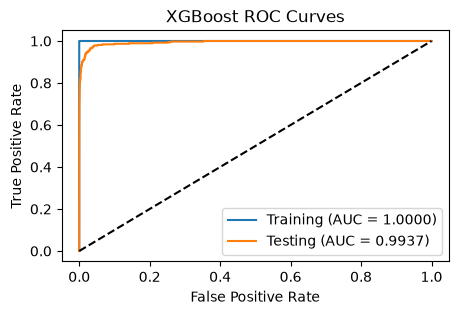

Using five-fold cross-validation, alpha = 0.1 was selected because it achieved the lowest average misclassification error among the tested values. The XGBoost model achieved nearly perfect training performance, while the test ROC curve showed strong performance with an AUC close to 1. The cross-validation error was also very close to the test error, suggesting that cross-validation provided a reasonable estimate of the model's performance on unseen data. Compared to the original Random Forest, XGBoost had a slightly lower test misclassification rate and identified more positive APS failures, despite not compensating for class imbalance.


In [6]:
# 1e) XGBoost and Model Trees
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1313)

# Make parameters consistent with when we do SMOTE
xgb = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), ("log", FunctionTransformer(np.log1p)), ("scaler", StandardScaler()),
    ("model", XGBClassifier(objective="binary:logistic", n_estimators=100, max_depth=6, 
                            tree_method="hist", n_jobs=4, random_state=1313, eval_metric="logloss"))
])

grid = GridSearchCV(
    xgb, param_grid={"model__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 50]},
    scoring={"auc": "roc_auc", "accuracy": "accuracy"}, refit="accuracy", cv=cv, n_jobs=1
)

grid.fit(X_train, y_train)

best_alpha = grid.best_params_["model__reg_alpha"]
cv_error = 1 - grid.best_score_
cv_auc = grid.cv_results_["mean_test_auc"][grid.best_index_]

print(f"Best Alpha: {best_alpha}")
print(f"CV AUC: {cv_auc:.4f}")
print(f"CV Error: {cv_error:.4f}")

# Evaluate the best model
best_xgb = grid.best_estimator_

plt.figure(figsize=(5, 3))

errors_xgb = {}
errors_xgb["Training"] = evaluate_model(best_xgb, "Training", X_train, y_train)
errors_xgb["Testing"] = evaluate_model(best_xgb, "Testing", X_test, y_test)

print(f"\nCV Error: {cv_error:.4f}")
print(f"Test Error: {errors_xgb["Testing"]:.4f}")
print("")

plt.plot([0, 1], [0, 1], color="black", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.show()

print("Using five-fold cross-validation, alpha = 0.1 was selected because it achieved the lowest average misclassification error among \
the tested values. The XGBoost model achieved nearly perfect training performance, while the test ROC curve showed strong performance \
with an AUC close to 1. The cross-validation error was also very close to the test error, suggesting that cross-validation provided a \
reasonable estimate of the model's performance on unseen data. Compared to the original Random Forest, XGBoost had a slightly lower \
test misclassification rate and identified more positive APS failures, despite not compensating for class imbalance.")

Best Alpha: 0.01
CV AUC: 0.9870
CV Error: 0.0066

--- TRAINING RESULTS ---
Confusion Matrix:
 [[59000     0]
 [    1   999]]
AUC: 1.0000
Misclassification Rate: 0.00001667

--- TESTING RESULTS ---
Confusion Matrix:
 [[15580    45]
 [   64   311]]
AUC: 0.9952
Misclassification Rate: 0.00681250

CV Error: 0.0066
Test Error: 0.0068



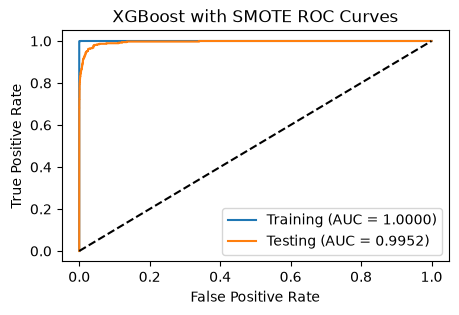

To address class imbalance, I applied SMOTE within each cross-validation training fold to avoid data leakage, while keeping the validation and test sets unchanged. Compared to the uncompensated XGBoost in 1e), the model with SMOTE achieved a slightly higher test AUC, suggesting improved ability to distinguish between the two classes. Although its overall misclassification rate increased slightly, the number of false negatives decreased from 84 to 64, meaning it was able to correctly identify more actual APS failures, at the expense of additional false positives. Since missing an actual APS failure is more costly than a false alarm, this trade-off may be preferable despite the slightly higher misclassification rate. Both models also had CV errors fairly close to their respective test errors, suggesting that cross-validation provided reasonable estimates of their performance on unseen data. Overall, SMOTE improved the model's ability to identify positive cases, despite slightly worsening

In [7]:
# 1f) SMOTE
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1313)

xgb_smote = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")), ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()), ("smote", SMOTE(random_state=1313)),
    ("model", XGBClassifier(objective="binary:logistic", n_estimators=100, max_depth=6, 
                            tree_method="hist", n_jobs=4, random_state=1313, eval_metric="logloss"))
])

grid_smote = GridSearchCV(
    xgb_smote, param_grid={"model__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 50]}, 
    scoring={"auc": "roc_auc", "accuracy": "accuracy"}, refit="accuracy", cv=cv, n_jobs=1
)

grid_smote.fit(X_train, y_train)

best_alpha_smote = grid_smote.best_params_["model__reg_alpha"]
cv_error_smote = 1 - grid_smote.best_score_
cv_auc_smote = grid_smote.cv_results_["mean_test_auc"][grid_smote.best_index_]

print(f"Best Alpha: {best_alpha_smote}")
print(f"CV AUC: {cv_auc_smote:.4f}")
print(f"CV Error: {cv_error_smote:.4f}")

# Evaluate the best model
best_xgb_smote = grid_smote.best_estimator_

plt.figure(figsize=(5, 3))

errors_smote = {}
errors_smote["Training"] = evaluate_model(best_xgb_smote, "Training", X_train, y_train)
errors_smote["Testing"] = evaluate_model(best_xgb_smote, "Testing", X_test, y_test)

print(f"\nCV Error: {cv_error_smote:.4f}")
print(f"Test Error: {errors_smote['Testing']:.4f}")
print("")

plt.plot([0, 1], [0, 1], color="black", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost with SMOTE ROC Curves")
plt.legend()
plt.show()

print("To address class imbalance, I applied SMOTE within each cross-validation training fold to avoid data leakage, while keeping the \
validation and test sets unchanged. Compared to the uncompensated XGBoost in 1e), the model with SMOTE achieved a slightly higher test \
AUC, suggesting improved ability to distinguish between the two classes. Although its overall misclassification rate increased slightly, \
the number of false negatives decreased from 84 to 64, meaning it was able to correctly identify more actual APS failures, at the \
expense of additional false positives. Since missing an actual APS failure is more costly than a false alarm, this trade-off may be \
preferable despite the slightly higher misclassification rate. Both models also had CV errors fairly close to their respective test \
errors, suggesting that cross-validation provided reasonable estimates of their performance on unseen data. Overall, SMOTE improved \
the model's ability to identify positive cases, despite slightly worsening its overall misclassification rate.")

### AI Attribution Statement

This assignment was completed with learning assistance from Google Gemini (Gemini 1.5 Pro), in accordance with the course syllabus and USC Academic Integrity policies regarding AI-assisted coursework.

#### 1. Formal MLA Citation
Google. *Gemini*. 1.5 Pro ed., Alphabet Inc., 4 Nov. 2026, https://gemini.google.com/. Prompted 4 Nov. 2026.

#### 2. Scope of AI Assistance
* **Imputation Benchmarking & Experimental Design:** Used as a thought partner to design leak-free cross-validation experiments comparing data imputation strategies (Median, Mean, Mode, KNN, and MICE) and evaluate their statistical stability and cost-metric performance.
* **Pipeline Hygiene & Syntax Auditing:** Used to validate that code snippets were correct (eg. no data leakage and proper cross-validation), and to audit code syntax for edge cases.
* **Visualization & Formatting:** Used to refine plot formatting, figure aesthetics, and color palettes for correlation heatmaps, log-scaled boxplots, and ROC curves using `matplotlib` and `seaborn`.
* **Conceptual Guidance & Polish:** Used as a thought partner to clarify theoretical statistical concepts (Lasso/Ridge Lagrangian mechanics, ISLR tree mechanics, and SVM maximal margins) and to polish prose for executive-level readability.

#### 3. Prompts Used
Representative prompts provided to the AI model during the completion of this assignment include:
* *"The following is from an earlier part of the conversation...train a random forest without compensating for class imbalance, what do you think of this code?"*
* *"Help me set up a leak-free cross-validation experiment comparing MICE, KNN, Median, and mean imputation strategies while avoiding data leakage."*
* *"What libraries are required for these imports to construct a valid requirements.txt file?"*

